# Feature construction without leakage

A model can only use the information it is given. After this block you can construct new input columns from dates, combinations of columns, categories with many levels and related tables, and you can build them inside a scikit-learn pipeline so that no information from the validation rows or from the future leaks into training. The running question: **which constructed features help a model of Berlin Airbnb prices and demand, and which ones only look as if they help?**

*Session 9, Block 1. Course material, licence CC BY 4.0. Sections marked "Adapted from" curate BSD-3-licensed examples of scikit-learn and skrub; see [extras/README.md](extras/README.md).*

## Overview

| Section | What it covers |
|---|---|
| Features from dates and times | date parts, elapsed time, seasonality of demand, cyclical encoding, ordinal, one-hot, sine/cosine and periodic spline encodings compared, dates known at prediction time |
| Interactions between features | the product column, room type × guests in Berlin, plotting an interaction, all pairwise products, splines, products of splines and the Nyström kernel |
| High-cardinality categories | cardinality, grouping rare levels with `min_frequency`, choosing the threshold, encoder options and unseen levels, count encoding, automatic encoding with skrub's `TableVectorizer` |
| Target encoding and its leakage risk | target encoding and smoothing, the naive leak and cross-fitting, a synthetic demonstration, `TargetEncoder` parameters, binary and multiclass targets, comparing encoders |
| Aggregation features from related tables | point-in-time aggregates, an out-of-time check, named aggregations, lags and rolling windows, daily to monthly tables, as-of joins, skrub's `AggJoiner` |
| Target leakage: inputs that are not known at the time of prediction | revenue and snapshot leaks, detecting leakage with permutation importance and a single-column scan, leakage through preprocessing, group leakage, a checklist |
| Custom transformers in scikit-learn pipelines | what a transformer is, `FunctionTransformer` and its options, a transformer class and the transformer contract, custom transformers in a pipeline, selecting columns by type and tuning preprocessing |
| Worked example | which constructed feature groups help the Berlin price model, for ridge regression and gradient boosting |
| Check your understanding, Exercises, Debrief | five questions, eight exercises in pairs, what to compare afterwards |

The flow of the block: each kind of raw input becomes features, and every step that learns from data sits in one pipeline.

```mermaid
flowchart LR
    raw["Raw columns<br/>dates, location, lists"] --> d["Date parts"]
    raw --> i["Interactions"]
    raw --> c["Categories<br/>rare grouping, target encoding"]
    rel["Related table<br/>monthly reviews"] --> a["Aggregates<br/>past rows only"]
    d --> p["Pipeline<br/>fitted on training rows only"]
    i --> p
    c --> p
    a --> p
    p --> m["Model"]
```

### Data

Inside Airbnb, Berlin, snapshot of 26 June 2026 (CC BY 4.0): the listings, the monthly review counts per listing and the daily Berlin weather from Open-Meteo, all in `case-study/data/airbnb/` (download `airbnb.zip` from the course drive and unzip it into `case-study/data/`, see [case-study/README.md](../../../case-study/README.md)). The data contain no host names; `host_id` only keeps a host's listings together in cross-validation (Session 7). The notebook runs in a few minutes.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## Features from dates and times

### Date parts

A **date part** is one component of a timestamp, computed as its own column. A timestamp such as `2025-12-24 18:05` is one value, but it carries several kinds of information: the **year** (a long-term trend), the **month** and **weekday** (seasons and weekly rhythms), the **hour** (a daily rhythm), whether the day is a **holiday**, and the **time elapsed** since some event (how long a host has been on the platform). A model cannot pull these parts out of a raw timestamp by itself; stored as a number, a timestamp is just a count of nanoseconds since 1970. We compute the parts as separate columns.

We load three tables. The price table of Sessions 6 to 8 keeps short-stay listings (minimum stay under 28 nights) with a price between €10 and €1,000; the target is the log of the nightly price.

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
reviews = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")   # listing_id, month, n_reviews
weather = pd.read_parquet("case-study/data/airbnb/weather_daily.parquet")     # one row per day since 2016

bnb = listings[(listings["minimum_nights"] < 28) & listings["price"].between(10, 1000)].reset_index(drop=True)
y = np.log(bnb["price"])            # target: log of the nightly price in EUR
hosts = bnb["host_id"]              # groups for cross-validation
print(len(listings), "listings,", len(bnb), "in the price table,", hosts.nunique(), "hosts,", len(weather), "days of weather")

10221 listings, 5277 in the price table, 2987 hosts, 3830 days of weather


Next we take the date parts of the weather table. The `.dt` accessor of a datetime column gives `.year`, `.month`, `.dayofweek` (Monday = 0), `.dayofyear` and many more; `.dt.day_name()` gives the weekday as text.

In [3]:
parts = pd.DataFrame({
    "date": weather["date"],
    "year": weather["date"].dt.year,
    "month": weather["date"].dt.month,
    "weekday": weather["date"].dt.dayofweek,
    "weekend": weather["date"].dt.dayofweek >= 5,
    "day_of_year": weather["date"].dt.dayofyear,
})
parts.tail(3)

,date,year,month,weekday,weekend,day_of_year
3827,2026-06-24,2026,6,2,False,175
3828,2026-06-25,2026,6,3,False,176
3829,2026-06-26,2026,6,4,False,177


### Elapsed time

An **elapsed-time** feature is the time between two events, such as the number of days since a listing's first review. Next we turn three listing dates into elapsed-time features and check whether they relate to the price. Subtracting two datetime columns gives a timedelta; `.dt.days` turns it into a number of days. `corrwith(y, method="spearman")` gives the rank correlation of each column with the target.

In [4]:
dates = pd.DataFrame({
    "host_years": bnb["hosts_time_as_host_years"],
    "listing_age_days": (bnb["last_scraped"] - bnb["first_review"]).dt.days,      # first review as proxy for the start
    "days_since_last_review": (bnb["last_scraped"] - bnb["last_review"]).dt.days,
})
print(dates.median().round(0).to_dict())
print(dates.corrwith(y, method="spearman").round(3).to_dict())

{'host_years': 6.0, 'listing_age_days': 1118.0, 'days_since_last_review': 20.0}


{'host_years': -0.014, 'listing_age_days': -0.04, 'days_since_last_review': 0.052}


An honest first result: these elapsed-time features say almost nothing about the price. The rank correlations with the log price lie between −0.04 and +0.05: a host who has been on Airbnb for ten years does not charge more than a newcomer. Checking such simple summaries before adding a feature to a model is good practice.

### Seasonality in demand

Dates matter more for a different question: **demand**. Reviews are a proxy for stays. Next we count what share of all Berlin reviews from 2023 to 2025 falls into each calendar month. `per_month.index.month` extracts the month number from a datetime index.

In [5]:
per_month = reviews.groupby("month")["n_reviews"].sum()
recent = per_month["2023-01-01":"2025-12-01"]
share = recent.groupby(recent.index.month).sum() / recent.sum()
print(share.round(3).to_dict())

{1: 0.053, 2: 0.058, 3: 0.069, 4: 0.081, 5: 0.093, 6: 0.1, 7: 0.102, 8: 0.094, 9: 0.103, 10: 0.097, 11: 0.076, 12: 0.073}


### Cyclical encoding

Demand is seasonal: January has 5.3 % of the year's reviews, June, July and September about 10 % each. A model of monthly demand needs the month. But some parts of a date are **cyclical**: December is followed by January, Sunday by Monday, 23:00 by 00:00. As a number from 1 to 12, a linear model sees December and January as 11 steps apart. A **cyclical encoding** puts each value on a circle, like the hand of a clock, with two columns:

- `month_sin = sin(2π · month / 12)`
- `month_cos = cos(2π · month / 12)`

Two columns are needed because one alone is ambiguous: February and April have the same sine (0.87), but their cosines differ (0.5 and −0.5).

![Months on the unit circle with their sine and cosine coordinates; December and January are neighbours](../figures/cyclical_month_encoding.png)

**Predict before running.** Which two of the three months below get the most similar pair of values?

In [6]:
cyc = pd.DataFrame({"month": [1, 7, 12]})
cyc["month_sin"] = np.sin(2 * np.pi * cyc["month"] / 12)
cyc["month_cos"] = np.cos(2 * np.pi * cyc["month"] / 12)
cyc.round(2)

,month,month_sin,month_cos
0,1,0.5,0.87
1,7,-0.5,-0.87
2,12,-0.0,1.00


January and December are neighbours on the circle; July sits opposite. Tree-based models (Session 10) can split a plain month number into ranges and usually do not need the sine and cosine; linear models and nearest-neighbour methods do.

### Comparing periodic encodings on Berlin temperatures

*Adapted from [Time-related feature engineering](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html) (scikit-learn developers, BSD-3-Clause), moved from hourly bike rentals to daily Berlin temperatures.*

A **periodic feature** is one whose values repeat in a cycle (day of the year, hour, weekday). Which encoding of a periodic feature works best for a linear model? We take a target with a clean yearly cycle, the **daily mean temperature in Berlin**, and predict it from the day of the year alone with four encodings:

1. **ordinal**: the day of the year as a number, scaled to 0–1. A linear model can only fit a straight line in it, so it cannot model "cold, warm, cold".
2. **one-hot month**: twelve dummy columns. Flexible, but it ignores the order of the months and jumps at each month boundary.
3. **sine and cosine** of the day of the year: smooth and periodic, but only one wave per year.
4. **periodic splines**: a set of smooth bumps spread over the year, each one a column. `SplineTransformer(extrapolation="periodic")` makes the last bump wrap round to the first, so 31 December and 1 January stay close.

Because the rows are ordered in time, we validate with `TimeSeriesSplit`: each fold trains on the past and tests on the following year (`test_size=365`). Next we define the encoders. `FunctionTransformer(func, feature_names_out="one-to-one")` turns a function into a transformer; the spline helper is copied from the scikit-learn example.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, OneHotEncoder, SplineTransformer


def sin_transformer(period):
    return FunctionTransformer(lambda x: np.sin(x / period * 2 * np.pi), feature_names_out="one-to-one")


def cos_transformer(period):
    return FunctionTransformer(lambda x: np.cos(x / period * 2 * np.pi), feature_names_out="one-to-one")


def periodic_spline_transformer(period, n_splines=None, degree=3):
    n_splines = n_splines or period
    n_knots = n_splines + 1                       # periodic and include_bias is True
    return SplineTransformer(degree=degree, n_knots=n_knots, extrapolation="periodic", include_bias=True,
                             knots=np.linspace(0, period, n_knots).reshape(n_knots, 1))

Next we look at what the encodings produce for each day of the year. The plot on the left shows the two trigonometric columns, the plot on the right the twelve spline columns: each is a bump that is non-zero for a few weeks.

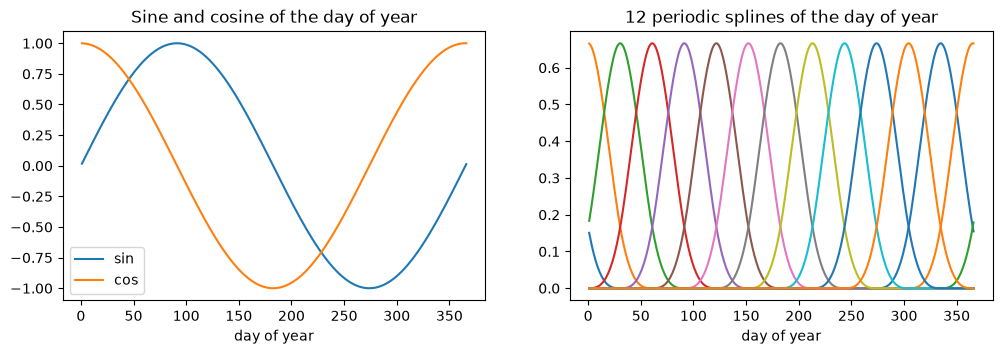

In [8]:
doy = pd.DataFrame({"day_of_year": np.arange(1, 367)})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
ax1.plot(doy, sin_transformer(365.25).fit_transform(doy), label="sin")
ax1.plot(doy, cos_transformer(365.25).fit_transform(doy), label="cos")
ax1.set(title="Sine and cosine of the day of year", xlabel="day of year")
ax1.legend()
ax2.plot(doy, periodic_spline_transformer(365.25, n_splines=12).fit_transform(doy))
ax2.set(title="12 periodic splines of the day of year", xlabel="day of year")
plt.show()

Next we build the four pipelines with `RidgeCV` (ridge regression that picks its penalty by internal cross-validation, Session 7) and evaluate each with the time-based splits. The score is the mean absolute error in °C.

In [9]:
Xw = parts[["day_of_year", "month"]]
temp = weather["temperature_2m_mean"]
ts_cv = TimeSeriesSplit(n_splits=5, test_size=365)          # train on the past, test on the next year
alphas = np.logspace(-6, 6, 25)
encodings = {
    "ordinal": ColumnTransformer([("doy", MinMaxScaler(), ["day_of_year"])]),
    "one-hot month": ColumnTransformer([("m", OneHotEncoder(handle_unknown="ignore"), ["month"])]),
    "sine and cosine": ColumnTransformer([("sin", sin_transformer(365.25), ["day_of_year"]),
                                          ("cos", cos_transformer(365.25), ["day_of_year"])]),
    "periodic splines": ColumnTransformer([("spl", periodic_spline_transformer(365.25, 12), ["day_of_year"])]),
}
for name, enc in encodings.items():
    res = cross_validate(make_pipeline(enc, RidgeCV(alphas=alphas)), Xw, temp, cv=ts_cv, scoring="neg_mean_absolute_error")
    print(f"{name:17s} MAE {-res['test_score'].mean():.2f} °C")

ordinal           MAE 6.31 °C
one-hot month     MAE 2.92 °C
sine and cosine   MAE 2.79 °C
periodic splines  MAE 2.78 °C


Next we fit each pipeline on all years but the last and plot its predictions for the last year next to the observed temperatures.

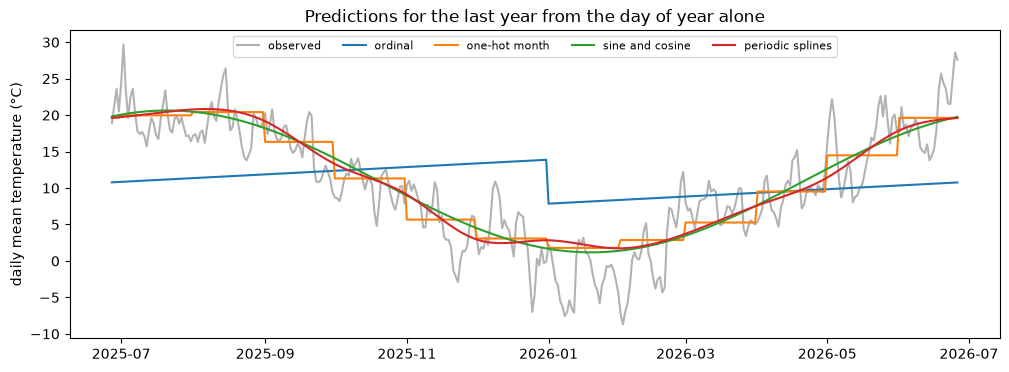

In [10]:
train_idx, test_idx = list(ts_cv.split(Xw))[-1]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(weather["date"].iloc[test_idx], temp.iloc[test_idx], color="black", alpha=0.3, label="observed")
for name, enc in encodings.items():
    pipe = make_pipeline(enc, RidgeCV(alphas=alphas)).fit(Xw.iloc[train_idx], temp.iloc[train_idx])
    ax.plot(weather["date"].iloc[test_idx], pipe.predict(Xw.iloc[test_idx]), label=name)
ax.set(ylabel="daily mean temperature (°C)", title="Predictions for the last year from the day of year alone")
ax.legend(ncol=5, fontsize=8)
plt.show()

The ordinal encoding is far off (MAE 6.31 °C): a straight line in the day of the year cannot go up and down again. The three periodic encodings are close: 2.92 °C for one-hot months, 2.79 °C for sine and cosine, 2.78 °C for 12 periodic splines. Temperature follows almost a single wave per year, the case in which sine and cosine are enough; the one-hot model predicts a step function that jumps at every month boundary. Most of the remaining error is day-to-day weather, which no calendar feature can know.

Lessons, in the words of the scikit-learn example: raw ordinal features miss the periodicity and jump at the end of each cycle; one-hot encoding is flexible but steps at every boundary and needs one column per level (1,440 for minutes of the day); sine and cosine are smooth but can express only one wave per period, unless we add higher harmonics; periodic splines give both smoothness and flexibility with few columns.

### Dates that are known at prediction time

> **Note.** Use only dates that are known when the prediction is made. A price tool for a *new* listing cannot use `first_review` or `last_review`: a new listing has no reviews yet. For timestamps with a time of day, convert to local time (`.dt.tz_convert("Europe/Berlin")`) before building hour features about human behaviour.

> 📖 **Read more:** [extras/01-time-related-feature-engineering.ipynb](extras/01-time-related-feature-engineering.ipynb) (scikit-learn gallery): the original study on hourly bike-sharing demand, with weekday and hour cycles, gradient boosting as a reference and a gap between training and test folds.

## Interactions between features

### What an interaction is: the product column

An **interaction** exists when the effect of one feature depends on the value of another. A linear or logistic regression adds up one effect per feature and cannot see this. We give it the interaction by adding the **product** of the two features as a new column.

An everyday example: a shop shows a discount banner. Suppose the discount barely moves ordinary visitors but makes members buy much more often. An additive model has one "discount effect" for everybody, so it gets both groups wrong. The next cell simulates this shop: members with a discount buy with probability 0.7, everyone else with 0.2. `PolynomialFeatures(degree=2, interaction_only=True)` adds the product `member × discount`.

In [11]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(0)
shop = pd.DataFrame({"member": rng.integers(0, 2, 2000), "discount": rng.integers(0, 2, 2000)})
shop["buy"] = rng.binomial(1, np.where((shop.member == 1) & (shop.discount == 1), 0.7, 0.2))

cells = pd.DataFrame({"member": [0, 0, 1, 1], "discount": [0, 1, 0, 1]})
plain = LogisticRegression().fit(shop[["member", "discount"]], shop["buy"])
inter = make_pipeline(PolynomialFeatures(2, interaction_only=True, include_bias=False),
                      LogisticRegression()).fit(shop[["member", "discount"]], shop["buy"])
cells["observed"] = shop.groupby(["member", "discount"])["buy"].mean().to_numpy()
cells["additive"] = plain.predict_proba(cells[["member", "discount"]])[:, 1]
cells["with_product"] = inter.predict_proba(cells[["member", "discount"]])[:, 1]
cells.round(2)

,member,discount,observed,additive,with_product
0,0,0,0.17,0.09,0.17
1,0,1,0.19,0.29,0.20
2,1,0,0.20,0.28,0.20
3,1,1,0.72,0.63,0.71


The additive model is wrong in every cell; with the product column the predictions match the observed rates.

### Room type × guests in Berlin

On the Berlin listings a natural candidate is **room type × size**: an extra guest place should be worth more in an entire flat (another bedroom) than in a private room (another bed in the same room). On the log scale we use `log(accommodates)`, whose coefficient is an **elasticity**: the percentage change of the price for a one-percent change in guests. We also construct the distance to Alexanderplatz in km from latitude and longitude (one degree of latitude is about 111.2 km; one degree of longitude in Berlin about 68.0 km).

**Predict before running.** Will the cross-validated R² rise a lot or a little when we add the product column?

In [12]:
from sklearn.model_selection import GroupKFold, cross_val_score

bnb["dist_km"] = np.hypot((bnb["latitude"] - 52.5219) * 111.2, (bnb["longitude"] - 13.4132) * 68.0)
base = pd.get_dummies(bnb["room_type"], dtype=int).drop(columns="Private room")    # private room = reference
base["log_guests"] = np.log(bnb["accommodates"])
base["dist_km"] = bnb["dist_km"]
with_inter = base.assign(log_guests_x_entire=base["log_guests"] * base["Entire home/apt"])

cv = GroupKFold(5)                                        # whole hosts per fold (Session 7)
for name, Xi in [("additive", base), ("+ interaction", with_inter)]:
    print(name, cross_val_score(LinearRegression(), Xi, y, cv=cv, groups=hosts, scoring="r2").mean().round(3))
print(pd.Series(LinearRegression().fit(with_inter, y).coef_, index=with_inter.columns).round(3).to_dict())

additive 0.5
+ interaction 0.502
{'Entire home/apt': 0.223, 'Hotel room': 0.521, 'Shared room': -0.859, 'log_guests': 0.409, 'dist_km': -0.024, 'log_guests_x_entire': 0.118}


The interaction exists: the guest elasticity is 0.41 for private rooms and 0.41 + 0.12 = 0.53 for entire flats, so doubling the guests raises the predicted price by about 2^0.41 − 1 ≈ 33 % for a room and 2^0.53 − 1 ≈ 44 % for a flat. But the cross-validated R² rises only from 0.500 to 0.502. The log scale already absorbs much of it: an effect that is multiplicative in euros is additive in log euros. A real interaction does not guarantee a better score.

#### Seeing the interaction

A plot makes the interaction visible: with an interaction the predicted price lines of the two room types have different slopes; without it they are parallel on the log scale. Next we predict the price for 1 to 8 guests at 5 km from the centre with both models.

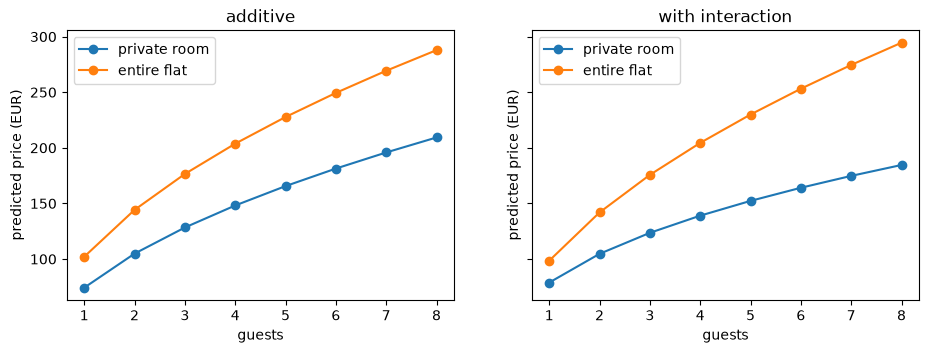

In [13]:
grid = pd.DataFrame({"log_guests": np.log(np.arange(1, 9))})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (title, Xi) in zip(axes, [("additive", base), ("with interaction", with_inter)]):
    lr = LinearRegression().fit(Xi, y)
    for room, entire in [("private room", 0), ("entire flat", 1)]:
        g = grid.assign(**{"Entire home/apt": entire, "Hotel room": 0, "Shared room": 0, "dist_km": 5.0})
        g["log_guests_x_entire"] = g["log_guests"] * entire
        ax.plot(np.arange(1, 9), np.exp(lr.predict(g[Xi.columns])), marker="o", label=room)
    ax.set(title=title, xlabel="guests", ylabel="predicted price (EUR)")
    ax.legend()
plt.show()

### All pairwise products

`PolynomialFeatures(degree=2, interaction_only=True)` creates every product of two columns. With *p* inputs it adds *p*·(*p*−1)/2 columns. Next we try it on eight numeric listing columns with a ridge model; `SimpleImputer` fills missing values and `StandardScaler` puts the columns on one scale before they are multiplied. `get_feature_names_out()` names the products, e.g. `accommodates bedrooms`.

In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_cols = ["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "review_scores_rating",
            "number_of_reviews", "minimum_nights"]
prep = [SimpleImputer(strategy="median"), StandardScaler()]
for name, extra in [("8 columns", []), ("+ all 28 products", [PolynomialFeatures(2, interaction_only=True, include_bias=False)])]:
    pipe = make_pipeline(*prep, *extra, RidgeCV(alphas=alphas))
    score = cross_val_score(pipe, bnb[num_cols], y, cv=cv, groups=hosts, scoring="r2").mean()
    print(f"{name:18s} R² {score:.3f}")
print(pipe[:-1].fit(bnb[num_cols]).get_feature_names_out(num_cols)[8:12])

8 columns          R² 0.408
+ all 28 products  R² 0.457
['accommodates bedrooms' 'accommodates beds' 'accommodates bathrooms'
 'accommodates dist_km']


Here the products help: R² rises from 0.408 to 0.457, so some pairs carry information that the eight columns alone do not. The gain is not guaranteed, though. Several columns have long tails (`number_of_reviews`, `minimum_nights`): the product of two large values is larger still, so a few listings can dominate the fit, and a different sample of listings can turn the gain into a loss. Treat all pairwise products as a candidate to validate, like any other feature group, and prefer products you can justify, such as room type × guests.

> **Note.** With 50 features, all pairwise products give 50 · 49 / 2 = 1,225 new columns, most of them noise, and the model overfits (Session 6). Add the interactions you can justify, or use a model that finds them itself (trees, Session 10). Scale the features before multiplying them, or the products have very different ranges.

### Splines, products and kernels

*Adapted from [Time-related feature engineering](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html), sections on pairwise interactions and kernels (scikit-learn developers, BSD-3-Clause).*

Products of raw columns capture only interactions of a simple shape. The scikit-learn example combines three ideas to make a linear model much more flexible:

- **splines** (`SplineTransformer`) let each numeric column have a curved effect, as in the comparison of periodic encodings but without the wrap-round;
- **products of spline columns** let one curve depend on another column;
- the **Nyström method** (`Nystroem(kernel="poly", degree=2)`) approximates *all* pairwise products of the spline columns at once with a fixed number of new columns, instead of building them explicitly.

Next we compare these, on distance, guests and room type, with gradient boosting, which finds interactions by itself.

In [15]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.kernel_approximation import Nystroem

pre = lambda: ColumnTransformer([("spl", SplineTransformer(n_knots=6), ["dist_km", "accommodates"]),
                                 ("room", OneHotEncoder(sparse_output=False), ["room_type"])])
models = {
    "splines, additive": make_pipeline(pre(), RidgeCV(alphas=alphas)),
    "splines + all products": make_pipeline(pre(), PolynomialFeatures(2, interaction_only=True, include_bias=False),
                                            RidgeCV(alphas=alphas)),
    "splines + Nystroem kernel": make_pipeline(pre(), Nystroem(kernel="poly", degree=2, n_components=300, random_state=0),
                                               RidgeCV(alphas=alphas)),
    "gradient boosting": HistGradientBoostingRegressor(random_state=0, categorical_features="from_dtype"),
}
Xs = bnb[["dist_km", "accommodates", "room_type"]].astype({"room_type": "category"})
for name, mdl in models.items():
    print(f"{name:26s} R² {cross_val_score(mdl, Xs, y, cv=cv, groups=hosts, scoring='r2').mean():.3f}")

splines, additive          R² 0.515


splines + all products     R² 0.524


splines + Nystroem kernel  R² 0.517


gradient boosting          R² 0.480


On these three inputs the spline models reach R² 0.52, slightly above gradient boosting with default settings (0.480). Explicit products of the spline columns add a little (0.515 → 0.524); the Nyström approximation barely does (0.517). With few inputs and a smooth relation, a well-engineered linear model can match a tree ensemble. The bike-sharing study in the extra shows the opposite case, where the kernel gives a large gain because the hourly pattern differs strongly between working days and weekends.

> 📖 **Read more:** [extras/01-time-related-feature-engineering.ipynb](extras/01-time-related-feature-engineering.ipynb) (scikit-learn gallery): the same comparison on bike rentals, where the interaction "working day × hour" makes the difference between commuter peaks and weekend use.

## High-cardinality categories

### Cardinality

The **cardinality** of a categorical column is its number of distinct values. `room_type` has 4 values; `neighbourhood` and `property_type` have many more, and many of their levels are rare. Postcodes, product codes or, in the team project, customs headings have thousands. One-hot encoding (Session 8) would create one column per level, many of them almost empty. A column with a single 1 among thousands of rows teaches a model nothing reliable but invites overfitting: the model can fit that one listing's price exactly.

### Grouping rare categories with `min_frequency`

**Grouping rare categories** replaces every level that appears fewer than *k* times in the training data by one shared level, "infrequent". The frequent levels keep their own column. Levels that appear only in new data join the shared group, so prediction does not fail on them.

Next we count the levels, and then let `OneHotEncoder(min_frequency=k, handle_unknown="infrequent_if_exist")` group the rare ones. `.transform(...).shape[1]` is the number of columns it produces.

In [16]:
for col in ["neighbourhood", "property_type"]:
    counts = bnb[col].value_counts()
    print(col, "levels:", len(counts), "| fewer than 20 listings:", (counts < 20).sum(), "| seen once:", (counts == 1).sum())

for k in [None, 20, 100]:
    enc = OneHotEncoder(min_frequency=k, handle_unknown="infrequent_if_exist")
    print("min_frequency", k, "-> columns:",
          [enc.fit(bnb[[c]]).transform(bnb[[c]]).shape[1] for c in ["neighbourhood", "property_type"]])

neighbourhood levels: 133 | fewer than 20 listings: 75 | seen once: 3
property_type levels: 53 | fewer than 20 listings: 34 | seen once: 10
min_frequency None -> columns: [133, 53]
min_frequency 20 -> columns: [59, 20]
min_frequency 100 -> columns: [14, 9]


#### Choosing the threshold

The threshold *k* is a hyperparameter: choose it with cross-validation (Session 7), not by looking at the test rows. Grouping happens inside `fit`, so in a pipeline the counts come from the training folds only.

Does grouping help a model? Next we vary `min_frequency` for `property_type` in a ridge model of the log price together with the size columns, scored with host-grouped cross-validation.

In [19]:
size_cols = ["accommodates", "bedrooms", "bathrooms"]
for k in [1, 5, 20, 100, 500]:
    ct = ColumnTransformer([("size", SimpleImputer(strategy="median"), size_cols),
                            ("pt", OneHotEncoder(min_frequency=k, handle_unknown="infrequent_if_exist"), ["property_type"])])
    score = cross_val_score(make_pipeline(ct, StandardScaler(with_mean=False), RidgeCV(alphas=alphas)),
                            bnb, y, cv=cv, groups=hosts, scoring="r2").mean()
    print(f"min_frequency {k:4d}  R² {score:.3f}")

min_frequency    1  R² 0.518


min_frequency    5  R² 0.523
min_frequency   20  R² 0.500


min_frequency  100  R² 0.464


min_frequency  500  R² 0.429


Grouping the levels with fewer than 5 listings gives the best score here (0.523, against 0.518 without grouping); coarser grouping throws information away (0.429 at 500). The best threshold depends on the data and the model, so tune it.

### Encoder options and unseen levels

`OneHotEncoder` offers several ways to limit the number of columns:

- `min_frequency=20` groups levels seen fewer than 20 times; `min_frequency=0.01` groups levels below 1 % of the rows.
- `max_categories=10` keeps at most 10 columns, the 9 most frequent levels plus "infrequent".
- `handle_unknown` decides what happens to a level that was not seen in `fit`: `"error"` (the default) stops, `"ignore"` encodes it as all zeros, `"infrequent_if_exist"` puts it in the infrequent column.

After fitting, `infrequent_categories_` lists the grouped levels. Next we fit on the property types and transform a level that does not exist in the data, "Treehouse". The grouped column is called `property_type_infrequent_sklearn`.

In [17]:
enc = OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist", sparse_output=False).fit(bnb[["property_type"]])
print(len(enc.infrequent_categories_[0]), "grouped levels, e.g.", list(enc.infrequent_categories_[0][:3]))
new = pd.DataFrame({"property_type": ["Entire rental unit", "Treehouse"]})
pd.DataFrame(enc.transform(new), columns=enc.get_feature_names_out()).iloc[:, -4:]

34 grouped levels, e.g. ['Barn', 'Boat', 'Camper/RV']


,property_type_Room in hotel,property_type_Room in serviced apartment,property_type_Shared room in hostel,property_type_infrequent_sklearn
0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0


Next we see the default behaviour on the same unseen level. We catch the error so that the notebook keeps running.

In [18]:
strict = OneHotEncoder().fit(bnb[["property_type"]])
try:
    strict.transform(new)
except ValueError as err:
    print("ValueError:", str(err)[:120])

ValueError: Found unknown categories ['Treehouse'] in column 0 during transform


In production, unseen levels are normal: a new property type, a new postcode, a new customs heading. Decide in advance what the encoder should do with them.

### Count encoding

A **count encoding** (or frequency encoding) replaces each level by how often it occurs in the training data. It gives one numeric column, and the frequency itself can carry information: rare property types (a houseboat, a campsite) behave differently from common ones. In pandas it is one `map`; in a model the counts must be learned in `fit` on the training rows only (exercise 1.8 builds that transformer).

In [20]:
counts = bnb["property_type"].value_counts()
bnb[["property_type"]].assign(count=bnb["property_type"].map(counts)).drop_duplicates().sort_values("count").head(4)

,property_type,count
4437,Hut,1
951,Private room in guest suite,1
3268,Shared room in home,1
3096,Shared room in condo,1


### Automatic encoding with skrub

*Adapted from [Encoding: from a dataframe to a numerical matrix for machine learning](https://skrub-data.org/stable/auto_examples/01_encoding/0010_encodings.html) (skrub developers, BSD-3-Clause), moved from employee salaries to Berlin listings.*

Choosing an encoder for every column by hand is tedious. The **skrub** library's `TableVectorizer` looks at each column and applies a default:

- numeric columns are passed through;
- datetime columns (also dates stored as text) are split into year, month, day and so on by a `DatetimeEncoder`;
- categorical or text columns with at most `cardinality_threshold=40` distinct values are one-hot encoded;
- columns with more values are encoded by a `StringEncoder`, which turns the text into a few numeric columns (a compressed bag of character n-grams), so that similar strings such as "Private room in rental unit" and "Private room in condo" get similar values.

`tabular_pipeline("regressor")` puts a `TableVectorizer` in front of a `HistGradientBoostingRegressor`. Next we give it a selection of raw listing columns, including the listing title and the amenity list, and cross-validate by host.

In [21]:
from skrub import TableVectorizer, tabular_pipeline

raw_cols = ["name", "neighbourhood", "district", "property_type", "room_type", "accommodates", "bedrooms",
            "bathrooms", "amenities", "host_is_superhost", "latitude", "longitude", "first_review"]
auto = tabular_pipeline("regressor")
print("host-grouped R²:", cross_val_score(auto, bnb[raw_cols], y, cv=cv, groups=hosts, scoring="r2").mean().round(3))

host-grouped R²: 0.604


Next we fit a `TableVectorizer` alone and inspect its choices. `kind_to_columns_` shows which columns it treated as numeric, datetime, low- or high-cardinality; `transformers_` gives the fitted transformer of each column.

In [22]:
vectorizer = TableVectorizer()
vec = vectorizer.fit_transform(bnb[raw_cols])
print(vec.shape[1], "output columns from", len(raw_cols), "inputs")
for kind, cols_ in vectorizer.kind_to_columns_.items():
    print(f"{kind:17s}", cols_)
print(vectorizer.transformers_["first_review"])

146 output columns from 13 inputs
numeric           ['accommodates', 'bedrooms', 'bathrooms', 'host_is_superhost', 'latitude', 'longitude']
datetime          ['first_review']
low_cardinality   ['district', 'room_type']
high_cardinality  ['name', 'neighbourhood', 'property_type', 'amenities']
specific          []
DatetimeEncoder()


Without any manual feature engineering the default pipeline reaches a host-grouped R² of about 0.60 (the exact value varies slightly from run to run), close to the hand-built pipeline in the section on custom transformers (0.611). The `TableVectorizer` turned 13 columns into 146: it recognised `first_review` as a date, one-hot encoded the two low-cardinality columns and encoded the four high-cardinality text columns, including the free-text title and the amenity list, with a `StringEncoder`. (`host_is_superhost` is a Boolean and counts as numeric.) Automatic encoding is a strong baseline that hand-made features have to beat; note that it also happily uses `first_review`, which a price tool for new listings must not use.

> 📖 **Read more:** [extras/02-table-vectorizer-encodings.ipynb](extras/02-table-vectorizer-encodings.ipynb) (skrub examples): the `TableVectorizer` on an employee-salary table, how to inspect and replace its encoders (`MinHashEncoder`, `GapEncoder`) and how the `GapEncoder` gives interpretable topics.

## Target encoding and its leakage risk

### Target encoding and smoothing

**Target encoding** (also called mean encoding) replaces each category by the mean of the target in the training rows of that category. For the price model, each neighbourhood becomes its mean log price: one numeric column instead of a hundred dummy columns, and it orders the neighbourhoods by price.

Two problems arise.

1. **Small categories give noisy means.** One listing says little about a whole neighbourhood. **Smoothing** pulls the mean of a small category towards the overall mean ȳ:

   encoding = (n · ȳ_category + m · ȳ) / (n + m)

   where n is the size of the category and m sets how strongly we pull. In words: a weighted average of the category mean (weight n) and the overall mean (weight m). Large categories hardly move; small ones move most. It is the same idea as a restaurant rating site that does not rank a restaurant with one five-star review above one with 500 reviews averaging 4.8.
2. **Leakage.** **Leakage** means that information that will not be available at prediction time enters the training data. If a row's own target is part of the mean that encodes it, the feature partly *is* the target. For a category with one row, the encoding equals the target exactly.

Next we compute the plain and the smoothed encoding (m = 10) and show the two smallest and the largest neighbourhood. `groupby(...).agg(n="size", mean="mean")` returns both numbers per level.

In [23]:
ybar, m = y.mean(), 10
enc_table = y.groupby(bnb["neighbourhood"]).agg(n="size", mean="mean")
enc_table["smoothed"] = (enc_table["n"] * enc_table["mean"] + m * ybar) / (enc_table["n"] + m)
print("overall mean log price", round(ybar, 2))
enc_table.sort_values("n").iloc[[0, 1, -1]].round(2)

overall mean log price 5.06


,n,mean,smoothed
neighbourhood,,,
Hellersdorf-Nord,1,3.85,4.95
West 3,1,4.60,5.02
Alexanderplatz,432,5.19,5.19


The two smallest neighbourhoods have one listing each, with log prices of 3.85 and 4.60 (about €47 and €100). Smoothing with m = 10 moves them to 4.95 and 5.02, close to the overall mean of 5.06. Alexanderplatz, with 432 listings, keeps its mean (5.19).

### The naive leak and cross-fitting

The remedy for the leak is **cross-fitting**: split the training rows into *k* folds and encode the rows of each fold with means computed from the other folds only. No row ever sees its own label. scikit-learn's `TargetEncoder` does this in `fit_transform` (5 folds by default) and smooths automatically (`smooth="auto"`, an empirical Bayes estimate of m). For new data, `transform` uses the means of the whole training set.

```mermaid
flowchart TB
    subgraph naive["Naive encoding"]
        n1["Mean per category<br/>from ALL training rows"] --> n2["Row i encoded with<br/>a mean that includes y_i"]
        n2 --> n3["Training score too high"]
    end
    subgraph cross["Cross-fitting (TargetEncoder.fit_transform)"]
        c1["Split training rows<br/>into 5 folds"] --> c2["Encode fold 1 with means<br/>of folds 2-5, and so on"]
        c2 --> c3["No row sees its own label"]
    end
```

To make the leak visible we encode `host_id`: many hosts have several listings with similar prices. We hold out 30 % of the hosts with `GroupShuffleSplit`, so the test rows imitate new hosts, and compare the naive encoding with the cross-fitted one. As a quick score, the squared correlation of one feature with the target is the R² of a line fitted on that feature.

**Predict before running.** For `host_id`, will the naive encoding look good on the training rows? On new hosts?

In [24]:
from sklearn.model_selection import GroupShuffleSplit, KFold
from sklearn.preprocessing import TargetEncoder

tr, te = next(GroupShuffleSplit(1, test_size=0.3, random_state=0).split(bnb, groups=hosts))
def r2(target, feature):
    # Squared correlation; a constant feature (every new host gets the overall mean) explains nothing.
    return round(np.corrcoef(target, feature)[0, 1] ** 2, 3) if np.std(feature) > 0 else 0.0


for col in ["host_id", "neighbourhood"]:
    naive = y.iloc[tr].groupby(bnb[col].iloc[tr]).mean()                # own row included
    f_tr = bnb[col].iloc[tr].map(naive)
    f_te = bnb[col].iloc[te].map(naive).fillna(y.iloc[tr].mean())       # unseen level: overall mean
    enc = TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=0))
    e_tr = enc.fit_transform(bnb[[col]].iloc[tr], y.iloc[tr]).ravel()   # cross-fitted
    e_te = enc.transform(bnb[[col]].iloc[te]).ravel()
    print(f"{col:13s} naive: train {r2(y.iloc[tr], f_tr)}, new hosts {r2(y.iloc[te], f_te)} | "
          f"cross-fitted: train {r2(y.iloc[tr], e_tr)}, new hosts {r2(y.iloc[te], e_te)}")

host_id       naive: train 0.817, new hosts 0.0 | cross-fitted: train 0.272, new hosts 0.0
neighbourhood naive: train 0.125, new hosts 0.063 | cross-fitted: train 0.063, new hosts 0.063


Read the numbers as "R² on training rows, R² on new hosts". The naive encoding of `host_id` explains 82 % of the variance on the training rows and nothing on new hosts, for whom every value is the overall mean. Most of the 82 % is the leak: hosts with one listing are encoded with their own price. The cross-fitted training R² of 0.27 is the part that is real for *known* hosts, whose other listings sit in other folds; a price tool for new hosts cannot use it. For `neighbourhood` the naive training R² (0.125) promises twice what the feature delivers on new hosts (0.063); the cross-fitted value (0.063) matches it. Here the neighbourhoods are large enough that a host's other listings in the same neighbourhood hardly move its mean; with smaller categories they can, because random cross-fitting folds put listings of the same host on both sides.

> **Note.** `TargetEncoder().fit(X, y).transform(X)` is **not** the same as `fit_transform(X, y)`: the first encodes the training rows with means that include their own labels. Inside a `Pipeline`, scikit-learn calls `fit_transform` during training and `transform` during prediction, which is correct. Cross-fitting protects against the row's own target, not against **groups** (a host's other listings) or the **future**: validate with groups or by time (Session 7).

In practice: Micci-Barreca (2001) proposed smoothed target statistics for attributes such as postcodes and IP addresses in fraud models; CatBoost (Session 10) encodes categories with *ordered target statistics*, where each row is encoded only with the labels of rows before it in a random order (Prokhorenkova et al., 2018).

#### A synthetic demonstration of cross-fitting

*Adapted from [Target Encoder's internal cross fitting](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder_cross_val.html) (scikit-learn developers, BSD-3-Clause).*

With real data we never know which category is truly informative. The scikit-learn example builds a dataset where we do know. It has a numeric target and three categorical features:

- `informative`: 100 categories that depend on the target (bins of the target plus noise, with the bin numbers shuffled so that the raw codes are useless to a linear model);
- `shuffled`: the same 100 categories, randomly permuted, so they carry no information;
- `near_unique`: almost one category per row, like a customer ID, and no information.

Next we generate the data. `KBinsDiscretizer` cuts a numeric variable into equal-width bins.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer

n_samples, n_categories = 50_000, 100
rs = np.random.RandomState(42)
y_syn = rs.randn(n_samples)
noise = 0.5 * rs.randn(n_samples)
kbins = KBinsDiscretizer(n_bins=n_categories, encode="ordinal", strategy="uniform", random_state=rs, subsample=None)
X_informative = kbins.fit_transform((y_syn + noise).reshape(-1, 1))
X_informative = rs.permutation(n_categories)[X_informative.astype(np.int32)]   # hide the order of the bins
X_shuffled = rs.permutation(X_informative)
X_near_unique = rs.choice(int(0.9 * n_samples), size=n_samples, replace=True).reshape(-1, 1)
X_syn = pd.DataFrame(np.concatenate([X_informative, X_shuffled, X_near_unique], axis=1),
                     columns=["informative", "shuffled", "near_unique"])
X_tr, X_te, y_tr, y_te = train_test_split(X_syn, y_syn, random_state=0)

Next we fit three ridge models: on the raw codes, with `TargetEncoder` inside a pipeline (cross-fitted), and with `fit` followed by `transform` (no cross-fitting). `.score` of a regressor is R².

**Predict before running.** Which model will have the best training score, and which the best test score?

In [26]:
from sklearn.linear_model import Ridge

ridge = lambda: Ridge(alpha=1e-6, solver="lsqr", fit_intercept=False)
raw = ridge().fit(X_tr, y_tr)
with_cf = make_pipeline(TargetEncoder(cv=KFold(shuffle=True, random_state=0)), ridge()).fit(X_tr, y_tr)
te_plain = TargetEncoder().fit(X_tr, y_tr)                  # fit, then transform: no cross-fitting
no_cf = ridge().fit(te_plain.transform(X_tr), y_tr)
for name, train, test in [("raw codes", raw.score(X_tr, y_tr), raw.score(X_te, y_te)),
                          ("cross-fitted", with_cf.score(X_tr, y_tr), with_cf.score(X_te, y_te)),
                          ("no cross-fitting", no_cf.score(te_plain.transform(X_tr), y_tr),
                           no_cf.score(te_plain.transform(X_te), y_te))]:
    print(f"{name:17s} train R² {train:.3f}   test R² {test:.3f}")

raw codes         train R² 0.005   test R² 0.005
cross-fitted      train R² 0.800   test R² 0.793
no cross-fitting  train R² 0.858   test R² 0.634


Next we compare the ridge coefficients of the two encoded models. A large weight on an uninformative feature is a sign of overfitting.

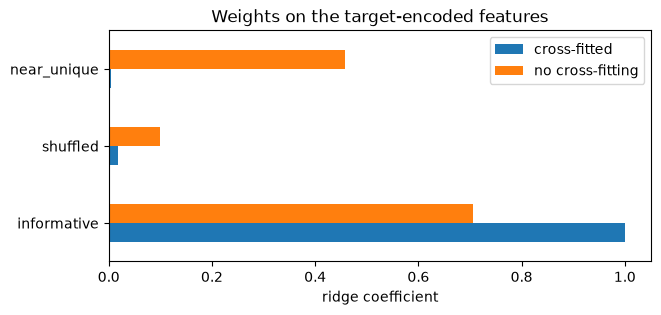

,cross-fitted,no cross-fitting
informative,1.001,0.706
shuffled,0.017,0.100
near_unique,0.005,0.457


In [27]:
coefs = pd.DataFrame({"cross-fitted": with_cf[-1].coef_, "no cross-fitting": no_cf.coef_}, index=X_syn.columns)
ax = coefs.plot.barh(figsize=(7, 3))
ax.set(xlabel="ridge coefficient", title="Weights on the target-encoded features")
plt.show()
coefs.round(3)

The raw codes are useless to a linear model (R² 0.005). With cross-fitting the model generalises (train 0.800, test 0.793) and puts its weight on the informative feature. Without cross-fitting the training score is higher (0.858) but the test score falls to 0.634: the shuffled and near-unique features, encoded with means that contain each row's own target, look informative on the training rows, and the ridge model gives them weight (0.46 for `near_unique` and 0.10 for `shuffled`, against 0.005 and 0.017 with cross-fitting). The same thing happened with `host_id` on the Berlin listings.

### `TargetEncoder` parameters and attributes

The main settings of `TargetEncoder`:

- `smooth`: `"auto"` (default) estimates the shrinkage from the variance within and between categories; a number fixes m as in the smoothing formula; `0` means no smoothing.
- `cv` and `shuffle`: the number of cross-fitting folds (default 5), or a splitter such as `KFold(5, shuffle=True, random_state=0)`.
- `target_type`: `"continuous"`, `"binary"` or `"multiclass"`; by default it is inferred from `y`.

After `fit`, `encodings_` holds the encoding of every category learned on all training rows, `categories_` the categories and `target_mean_` the overall mean. Next we compare the encoding of the three smallest neighbourhoods for three smoothing settings.

In [28]:
small = enc_table.sort_values("n").index[:3]
rows = {}
for s in [0.0, "auto", 100.0]:
    te_s = TargetEncoder(target_type="continuous", smooth=s).fit(bnb[["neighbourhood"]], y)
    lookup = pd.Series(te_s.encodings_[0], index=te_s.categories_[0])
    rows[f"smooth={s}"] = lookup[small]
print("target_mean_", round(te_s.target_mean_, 3))
pd.DataFrame(rows).assign(n=enc_table.loc[small, "n"]).round(2)

target_mean_ 5.061


,smooth=0.0,smooth=auto,smooth=100.0,n
neighbourhood,,,,
Hellersdorf-Nord,3.85,3.85,5.05,1
West 3,4.60,4.60,5.06,1
Gropiusstadt,4.76,4.76,5.06,1


A surprise worth knowing: with `smooth="auto"` the one-listing neighbourhoods are **not** shrunk at all (3.85, 4.60 and 4.76, as without smoothing), while a fixed `smooth=100` pulls them to about 5.05. For a continuous target, the automatic shrinkage of a category depends on the spread of the target *within* that category (Micci-Barreca, 2001, eq. 5 and 6, as implemented in scikit-learn); a category with a single row has no spread, so it is treated as perfectly reliable. Cross-fitting still prevents the leak of the row's own target in `fit_transform`, but at prediction time such a category gets its one training value. Group rare levels first (`min_frequency`, see high-cardinality categories) or set `smooth` to a number.

### Binary and multiclass targets

For a **binary** target the encoding is the smoothed share of positives per category. For a **multiclass** target with *K* classes, `TargetEncoder` creates *K* columns per feature: the smoothed share of each class. Next we encode the neighbourhood against the room type (4 classes), for example to describe what kind of offer dominates an area.

In [29]:
te_multi = TargetEncoder(target_type="multiclass", cv=KFold(5, shuffle=True, random_state=0))
multi = te_multi.fit_transform(bnb[["neighbourhood"]], bnb["room_type"])
print(multi.shape, te_multi.classes_)
print(te_multi.get_feature_names_out())

(5277, 4) ['Entire home/apt' 'Hotel room' 'Private room' 'Shared room']
['neighbourhood_Entire home/apt' 'neighbourhood_Hotel room'
 'neighbourhood_Private room' 'neighbourhood_Shared room']


With a thousand classes, a multiclass target encoding would create a thousand columns per feature, as many as the one-hot encoding we wanted to avoid; then one encodes against a coarser target (for example the first two digits of a customs heading).

### Comparing encoders

*Adapted from [Comparing Target Encoder with other encoders](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder.html) (scikit-learn developers, BSD-3-Clause), moved from wine reviews to Berlin listings.*

How do the encodings compare inside a gradient-boosting model? We encode `neighbourhood`, `property_type` and `room_type` in five ways:

- **drop**: leave the categories out;
- **ordinal**: number the categories 0, 1, 2, ... in an arbitrary order;
- **one-hot** with `max_categories=20`;
- **target** encoding;
- **native**: `HistGradientBoostingRegressor` with `categorical_features`, which splits categories directly (possible for up to 255 levels).

Next we define a helper that cross-validates a pipeline by host and records the root mean squared error (RMSE) of the log price on the training and on the test folds. `cross_validate(..., return_train_score=True)` returns both.

In [30]:
from sklearn.preprocessing import OrdinalEncoder

cat_cols, num_feats = ["neighbourhood", "property_type", "room_type"], ["accommodates", "bedrooms", "bathrooms", "dist_km"]
results = []


def evaluate_encoder(name, pipe):
    res = cross_validate(pipe, bnb[num_feats + cat_cols], y, cv=cv, groups=hosts,
                         scoring="neg_root_mean_squared_error", return_train_score=True)
    results.append({"encoder": name, "train RMSE": -res["train_score"].mean(), "test RMSE": -res["test_score"].mean()})

Next we run the four `ColumnTransformer` variants and the native one. For the native variant the preprocessor must output a pandas data frame (`set_output(transform="pandas")`) so that the model can find the categorical columns by name.

In [31]:
hgb = lambda **kw: HistGradientBoostingRegressor(random_state=0, **kw)
encoders = {"drop": "drop",
            "ordinal": OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            "one-hot": OneHotEncoder(handle_unknown="ignore", max_categories=20, sparse_output=False),
            "target": TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=0))}
for name, enc in encoders.items():
    pre_ = ColumnTransformer([("num", "passthrough", num_feats), ("cat", enc, cat_cols)])
    evaluate_encoder(name, make_pipeline(pre_, hgb()))
native_pre = ColumnTransformer([("num", "passthrough", num_feats),
                                ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)],
                               verbose_feature_names_out=False).set_output(transform="pandas")
evaluate_encoder("native", make_pipeline(native_pre, hgb(categorical_features=cat_cols)))
pd.DataFrame(results).set_index("encoder").round(4)

,train RMSE,test RMSE
encoder,,
drop,0.3452,0.4252
ordinal,0.2877,0.3826
one-hot,0.3021,0.3836
target,0.3078,0.3825
native,0.2693,0.3834


All encodings beat dropping the categories (test RMSE 0.425 against about 0.383). The four encodings are practically tied: target (0.3825), ordinal (0.3826), native categorical support (0.3834) and one-hot (0.3836) differ only in the fourth decimal. The native variant has the lowest training error (0.269) but not the lowest test error: it fits the training folds most closely. With 133 and 53 levels the differences are small; with thousands of levels one-hot encoding needs a cap and native support is not available (the limit is 255 levels).

The scikit-learn example explains the general pattern: dropping the categories underfits; one-hot with a cap on the number of columns can underfit and, without the cap, overfits on rare levels; ordinal codes impose an arbitrary order, so the boosting model's bins mix unrelated categories; target encoding orders the categories by their association with the target, so the bins make sense, and smoothing plus cross-fitting regularise it.

> 📖 **Read more:** [extras/03-target-encoder.ipynb](extras/03-target-encoder.ipynb) and [extras/04-target-encoder-cross-fitting.ipynb](extras/04-target-encoder-cross-fitting.ipynb) (scikit-learn gallery): the original comparison on wine reviews with categories above 255 levels, and the original synthetic cross-fitting study.

## Aggregation features from related tables

### Point-in-time aggregates

An **aggregate feature** summarises many rows of a related table into one value per prediction row: a count, a sum, the most recent value, the time since the first event. The table `reviews_monthly` has one row per listing and month. Grouped by listing it gives features such as "reviews in the last 12 months". This is a one-to-many relation: one listing, many review months; one customer, many orders; one shopping basket, many products.

A question that needs them: **which listings will be busy next year?** A cleaning company planning staff, or a city office that monitors short-term rentals, wants to know in advance. We place ourselves on **1 July 2025** and predict the number of reviews from July 2025 to June 2026.

The rule for a correct aggregate: **use only rows that were known at the moment of prediction**. Such features are called **point-in-time correct**. A bank that predicts whether you will repay a loan may look at your past payments, not at the payments you make after the decision.

Worked example: one listing with reviews in five months.

| month | reviews | used for a prediction on 1 July 2025? |
|---|---|---|
| 2024-05 | 2 | yes (but not in "last 12 months") |
| 2024-08 | 3 | yes |
| 2025-04 | 1 | yes (also in "last 3 months") |
| 2025-09 | 4 | no: target period |
| 2026-02 | 2 | no: target period |

As of 1 July 2025: `rev_total` = 6, `rev_last12` = 4, `rev_last3` = 1. Target: 6 reviews.

```mermaid
flowchart LR
    past["Review months<br/>before 1 July 2025"] -->|"features"| f["rev_total, rev_last12,<br/>rev_last3, months_since_last"]
    fut["Review months<br/>July 2025 to June 2026"] -->|"target only"| t["reviews next year"]
```

Next we write one function that builds the table for any cut-off date. The pattern is: **filter first, then aggregate**. `pd.DateOffset(months=12)` moves a date by twelve months; `join(..., how="inner")` keeps listings with at least one review before the cut-off.

In [32]:
def demand_table(cutoff):
    cutoff = pd.Timestamp(cutoff)
    past = reviews[reviews["month"] < cutoff]                                       # known at the cut-off
    future = reviews[(reviews["month"] >= cutoff) & (reviews["month"] < cutoff + pd.DateOffset(months=12))]
    last = lambda k: past[past["month"] >= cutoff - pd.DateOffset(months=k)].groupby("listing_id")["n_reviews"].sum()
    g = past.groupby("listing_id")
    feat = pd.DataFrame({"rev_total": g["n_reviews"].sum(), "rev_last12": last(12), "rev_last3": last(3),
                         "months_since_first": (cutoff - g["month"].min()).dt.days / 30.44,
                         "months_since_last": (cutoff - g["month"].max()).dt.days / 30.44}).fillna(0)
    table = listings.set_index("id").join(feat, how="inner")
    table["target"] = future.groupby("listing_id")["n_reviews"].sum().reindex(table.index).fillna(0)
    return table


demand = demand_table("2025-07-01")
print(len(demand), "listings | median target", demand["target"].median(),
      "| share with no review next year", round((demand["target"] == 0).mean(), 3))

7071 listings | median target 3.0 | share with no review next year 0.379


Next we model `log(1 + reviews next year)` with gradient boosting (Session 10 explains how it works; here it is just a flexible model) and compare it with the simple rule "next year = last year". `np.log1p` computes log(1 + x), which handles zero counts.

In [33]:
from sklearn.metrics import r2_score

past_only = ["rev_total", "rev_last12", "rev_last3", "months_since_first", "months_since_last", "accommodates"]
y_d = np.log1p(demand["target"])
gbm = HistGradientBoostingRegressor(random_state=0)
r2_past = cross_val_score(gbm, demand[past_only], y_d, cv=cv, groups=demand["host_id"], scoring="r2").mean()
print("past-only model R²", round(r2_past, 3),
      "| 'next year = last year' R²", round(r2_score(y_d, np.log1p(demand["rev_last12"])), 3))

past-only model R² 0.823 | 'next year = last year' R² 0.76


### An out-of-time check

An **out-of-time check** trains on data up to one date and tests on a later period. Cross-validation within one cut-off still mixes listings of the same period. The real use of such a model is out of time: train on an earlier cut-off, predict a later one. Next we train on the table of 1 July 2024 and test on 1 July 2025.

In [34]:
earlier = demand_table("2024-07-01")
model = HistGradientBoostingRegressor(random_state=0).fit(earlier[past_only], np.log1p(earlier["target"]))
print("trained on 2024-07-01 (", len(earlier), "listings ), R² on 2025-07-01:",
      round(r2_score(y_d, model.predict(demand[past_only])), 3))

trained on 2024-07-01 ( 6056 listings ), R² on 2025-07-01: 0.816


7,071 listings had at least one review before July 2025; 38 % of them received none in the following year. The past-only model explains 82 % of the variance of log(1 + reviews), against 76 % for the rule "next year = last year". Trained a year earlier, it still reaches 0.816 on the later cut-off, so the relation carries over in time. In SQL (Session 3) the same features are a filtered `GROUP BY`, or a window function such as `SUM(n_reviews) OVER (PARTITION BY listing_id ORDER BY month ROWS BETWEEN 12 PRECEDING AND 1 PRECEDING)`.

> **Note.** The snapshot only contains listings that still exist in June 2026. Listings that left Airbnb during the year are missing, so the share of "no reviews next year" is too low and both scores are optimistic (**survivorship bias**). A listing without any past review has no history: in a real system keep it with counts of 0 and an indicator "no review yet" instead of dropping it.

### More summary statistics

A sum is only one way to summarise a history. `groupby(...).agg(...)` with **named aggregations** computes several statistics at once: `name=("column", "function")`. Next we add the mean, maximum and standard deviation of the monthly counts and the number of active months before the cut-off, and check whether they improve the demand model.

In [35]:
cut = pd.Timestamp("2025-07-01")
stats = (reviews[reviews["month"] < cut].groupby("listing_id")
         .agg(rev_mean=("n_reviews", "mean"), rev_max=("n_reviews", "max"),
              rev_std=("n_reviews", "std"), active_months=("n_reviews", "size")))
demand2 = demand.join(stats)
more = past_only + list(stats.columns)
print(stats.describe().loc[["mean", "50%", "max"]].round(1))
print("R² with more statistics:", cross_val_score(gbm, demand2[more], y_d, cv=cv, groups=demand["host_id"], scoring="r2").mean().round(3))

      rev_mean  rev_max  rev_std  active_months
mean       2.2      4.5      1.2           20.6
50%        1.7      3.0      1.0           10.0
max       42.9    123.0     25.1          144.0


R² with more statistics: 0.82


The extra statistics do not help (0.820 against 0.823): the sums over recent windows already say what the mean and the maximum say. A feature that is plausible and correctly built can still add nothing; then keep the simpler model.

### Lags and rolling windows

When we predict every month instead of once, each row of the training table is a (listing, month) pair, and each row needs its own history. Two pandas tools build such features:

- `shift(1)` within a group moves the values one row down, so each month sees the previous month: a **lag**.
- `rolling(3).sum()` sums a moving window of 3 rows.

The order matters: **shift first, then roll**. A rolling sum without the shift includes the current month, which is the value we want to predict. Next we build both versions for one listing. The table has rows only for months with reviews, so we first fill the missing months with 0 (`asfreq("MS", fill_value=0)` sets a monthly frequency).

In [36]:
h1 = reviews[reviews["month"].between("2025-01-01", "2025-07-01")].groupby("listing_id")["n_reviews"].agg(["size", "sum"])
one_id = h1[h1["size"] == 7].sort_values("sum").index[len(h1[h1["size"] == 7]) // 2]   # active every month
s = reviews[reviews["listing_id"] == one_id].set_index("month")["n_reviews"].asfreq("MS", fill_value=0)
panel = pd.DataFrame({"n_reviews": s,
                      "lag1": s.shift(1),
                      "past3_correct": s.shift(1).rolling(3).sum(),     # three months before this month
                      "past3_leaky": s.rolling(3).sum()})               # includes this month
panel["2025-01-01":"2025-06-01"]

,n_reviews,lag1,past3_correct,past3_leaky
month,,,,
2025-01-01,3,2.0,13.0,8.0
2025-02-01,4,3.0,8.0,9.0
2025-03-01,5,4.0,9.0,12.0
2025-04-01,2,5.0,12.0,11.0
2025-05-01,6,2.0,11.0,13.0
2025-06-01,2,6.0,13.0,10.0


With many listings, use `groupby("listing_id")["n_reviews"].shift(1)` so that one listing's history does not slide into the next listing's rows, and sort by listing and month first.

### Aggregating a daily table to months

Tables often come at different time resolutions. The weather is daily; demand is monthly. `resample("MS").mean()` turns the daily table into one row per month, which can then be joined on the month.

Next we compute the monthly mean temperature and join it to the monthly review totals of Berlin. Do warmer months have more reviews?

In [37]:
monthly_weather = weather.set_index("date").resample("MS").agg({"temperature_2m_mean": "mean", "precipitation_sum": "sum"})
city = per_month.rename("reviews").to_frame().join(monthly_weather, how="inner")["2023-01-01":"2025-12-01"]
print(len(city), "months;", "rank correlation of reviews with temperature:",
      round(city["reviews"].corr(city["temperature_2m_mean"], method="spearman"), 2))
city.head(3).round(1)

36 months; rank correlation of reviews with temperature: 0.66


,reviews,temperature_2m_mean,precipitation_sum
month,,,
2023-01-01,3911,4.1,67.5
2023-02-01,4170,2.9,46.9
2023-03-01,4765,5.4,86.7


### As-of joins

An **as-of join** is a join on the latest earlier row. `pd.merge_asof(left, right, on="date", by="key", allow_exact_matches=False)` attaches to each left row the latest right row of the same key *strictly before* its date: the value "as of" that moment. Both tables must be sorted by the date.

Next an as-of join on a small example: three prediction requests for one listing, each with the latest monthly review count before the request date.

In [38]:
history = reviews[reviews["listing_id"] == one_id].sort_values("month")
requests = pd.DataFrame({"listing_id": one_id,
                         "date": pd.to_datetime(["2025-03-15", "2025-07-01", "2025-07-20"]).astype(history["month"].dtype)})
pd.merge_asof(requests, history, left_on="date", right_on="month", by="listing_id", allow_exact_matches=False)

,listing_id,date,month,n_reviews
0,23298585,2025-03-15,2025-03-01,5
1,23298585,2025-07-01,2025-06-01,2
2,23298585,2025-07-20,2025-07-01,4


For the request on 1 July, `allow_exact_matches=False` makes sure that the month starting on that day is not used; for 20 July, the month of July is used, although the month is not over yet. Monthly rows are stamped with the first day of the month, but they are only complete at its end: shift such timestamps to the moment the value is actually known.

### Aggregation inside a pipeline with skrub's `AggJoiner`

*Adapted from [AggJoiner on a credit fraud dataset](https://skrub-data.org/stable/auto_examples/03_joining/0070_join_aggregation.html) (skrub developers, BSD-3-Clause), moved from shopping baskets to Berlin listings.*

In the skrub example, a fraud model scores shopping baskets, and each basket has many products. Flattening the products into one wide row per basket creates hundreds of mostly empty columns. The better way is to **aggregate then join**: summarise the products per basket (minimum, maximum, mean, sum) and join the summaries to the basket table. skrub's `AggJoiner` does this as a transformer, so it can sit in a pipeline:

- `aux_table`: the related table (here the review months), given when the transformer is created;
- `main_key` and `aux_key`: the key columns in the main and the related table;
- `cols` and `operations`: what to aggregate and how.

Next we use it for the demand model, once with the review rows before the cut-off and once with the whole review table. `DropCols` removes the key afterwards.

**Predict before running.** Which of the two will look better in cross-validation, and which one can we use?

In [39]:
from skrub import AggJoiner, DropCols

main = demand.reset_index()[["id", "accommodates", "host_id"]]
for name, aux in [("past rows only", reviews[reviews["month"] < cut]), ("whole review table", reviews)]:
    agg_model = make_pipeline(
        AggJoiner(aux_table=aux, main_key="id", aux_key="listing_id", cols=["n_reviews"],
                  operations=["sum", "mean", "max", "count"]),
        DropCols(["id", "host_id"]), HistGradientBoostingRegressor(random_state=0))
    score = cross_val_score(agg_model, main, y_d.to_numpy(), cv=cv, groups=main["host_id"], scoring="r2").mean()
    print(f"{name:19s} R² {score:.3f}")

past rows only      R² 0.486


whole review table  R² 0.648


The version with all review rows looks far better (R² 0.648 against 0.486), and it is useless: its sums include the year we are predicting. `AggJoiner` aggregates whatever table it is given; the point-in-time filter is our job. The honest `AggJoiner` model also scores below the hand-built point-in-time table (0.823), because a sum over all past months has no sense of recency: the last 3 and 12 months and the months since the last review carry most of the signal.

The skrub example names two limits of this design: the related table is stored inside the fitted model, which makes it large on disk, and new related data (next month's reviews) can only be used by replacing that table by hand. skrub also has `AggTarget`, which aggregates the *target* per key: that is target encoding through a join and needs the same care as target encoding.

> 📖 **Read more:** [extras/05-join-aggregation.ipynb](extras/05-join-aggregation.ipynb) (skrub examples): the original fraud-detection example with two chained `AggJoiner`s, `MinHashEncoder` columns and a tuned gradient-boosting classifier.

## Target leakage: inputs that are not known at the time of prediction

### Revenue and snapshot leaks

**Target leakage** is the use of information that would not be available when the prediction is made and that is related to the target. Three typical forms:

1. **Columns derived from the target.** Inside Airbnb estimates each listing's occupancy from its reviews and computes `estimated_revenue_l365d` from occupancy and price. For a price model, revenue contains the price.
2. **Aggregates that include the target period.** The snapshot columns `number_of_reviews_ltm` (reviews in the last twelve months), `reviews_per_month` and `estimated_occupancy_l365d` were computed in June 2026, so they cover exactly the year we predict in the demand model.
3. **Information written with or after the label**, such as a "reason for cancellation" in a churn table, or the written justification that accompanies an expert's decision (Session 13 meets one in the customs case study).

Leakage is dangerous because it is silent: every number in the notebook improves. It shows only on truly new data, after deployment.

```mermaid
flowchart LR
    subgraph before["Before 1 July 2025"]
        p1["Review months<br/>up to June 2025"]
    end
    subgraph target["July 2025 to June 2026"]
        r["Reviews = target"]
    end
    subgraph snapshot["Snapshot, June 2026"]
        s1["number_of_reviews_ltm,<br/>reviews_per_month,<br/>estimated occupancy"]
        s2["estimated revenue<br/>from occupancy and price"]
    end
    p1 -->|"allowed"| feat["Demand features"]
    r -.->|"computed from<br/>the target period"| s1
    s1 -.->|"leak"| feat
    s2 -.->|"leak: contains the price"| pricef["Price features"]
```

Next we add revenue and occupancy to a simple price model. `pd.get_dummies` one-hot encodes the two categorical columns.

**Predict before running.** By how much will R² rise?

In [40]:
cols = ["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "room_type", "district",
        "review_scores_rating", "number_of_reviews", "minimum_nights", "availability_365"]
price_X = pd.get_dummies(bnb[cols], columns=["room_type", "district"], dtype=int)
leaky = price_X.assign(revenue=bnb["estimated_revenue_l365d"], occupancy=bnb["estimated_occupancy_l365d"])
for name, Xi in [("honest", price_X), ("+ revenue and occupancy", leaky)]:
    print(name, cross_val_score(gbm, Xi, y, cv=cv, groups=hosts, scoring="r2").mean().round(3))

honest 0.601


+ revenue and occupancy 0.861


The demand model of the aggregation section has its own leak. Next we add the June 2026 snapshot columns to the past-only features, and separately two columns that look harmless: `availability_365` and `minimum_nights`, also measured in June 2026.

In [41]:
snapshot_cols = ["number_of_reviews_ltm", "reviews_per_month", "estimated_occupancy_l365d"]
for name, extra in [("past-only", []), ("+ snapshot review columns", snapshot_cols),
                    ("+ availability_365, minimum_nights", ["availability_365", "minimum_nights"])]:
    score = cross_val_score(gbm, demand[past_only + extra], y_d, cv=cv, groups=demand["host_id"], scoring="r2").mean()
    print(f"{name:36s} R² {score:.3f}")
print("number_of_reviews_ltm equals the target for", round((demand["number_of_reviews_ltm"] == demand["target"]).mean(), 3))

past-only                            R² 0.823


+ snapshot review columns            R² 0.999


+ availability_365, minimum_nights   R² 0.848
number_of_reviews_ltm equals the target for 0.847


| Question | Features | Host-grouped R² | Verdict |
|---|---|---|---|
| price | size, location, room type, reviews | 0.601 | honest |
| price | + estimated revenue and occupancy | 0.861 | leak: revenue and occupancy reveal the price |
| demand next year | past-only review aggregates + size | 0.823 | honest |
| demand next year | + snapshot review columns | 0.999 | leak: `number_of_reviews_ltm` equals the target for 85 % of the listings |
| demand next year | + availability and minimum stay of June 2026 | 0.848 | subtle leak: measured after the cut-off |

The revenue columns lift the price model from 0.60 to 0.86; a new listing has no revenue history, and an existing one has its revenue only *because* of its price. The snapshot review columns make the demand model almost perfect, because they count the very reviews we want to predict. The last row is the instructive one: availability looks like a harmless property of a listing, but measured in June 2026 it probably reflects in part whether the listing is still active, which is what the model is asked to predict. Two to three points of R² for a subtle leak are enough to change a model choice.

### Detecting leakage

Three checks:

- **Too good to be true.** A jump in the score, or one feature far more important than all others. **Permutation importance** (Session 10) shuffles one column on held-out rows and measures how much the score drops.
- **Read the data dictionary.** Inside Airbnb documents how its derived columns are computed.
- **Ask for each feature:** *at which moment is this value known, and from which rows is it computed?*

#### Permutation importance

Next we compute the permutation importance of the leaky price model on held-out hosts. `permutation_importance(model, X_test, y_test, n_repeats=5)` returns the mean drop in R² per column.

In [42]:
from sklearn.inspection import permutation_importance

tr2, te2 = next(GroupShuffleSplit(1, test_size=0.25, random_state=0).split(leaky, groups=hosts))
fitted = HistGradientBoostingRegressor(random_state=0).fit(leaky.iloc[tr2], y.iloc[tr2])
perm = permutation_importance(fitted, leaky.iloc[te2], y.iloc[te2], scoring="r2", n_repeats=5, random_state=0)
pd.Series(perm.importances_mean, index=leaky.columns).sort_values(ascending=False).head(4).round(3)

revenue             2.921
occupancy           2.201
accommodates        0.036
availability_365    0.025
dtype: float64

Next we confirm the reason with the data: for listings with some occupancy, revenue divided by occupancy should equal the price.

In [43]:
occupied = bnb["estimated_occupancy_l365d"] > 0
ratio = bnb.loc[occupied, "estimated_revenue_l365d"] / bnb.loc[occupied, "estimated_occupancy_l365d"]
print("share with occupancy > 0:", round(occupied.mean(), 3),
      "| revenue / occupancy within 1 % of the price:", round((np.abs(ratio / bnb.loc[occupied, "price"] - 1) < 0.01).mean(), 3))

share with occupancy > 0: 0.865 | revenue / occupancy within 1 % of the price: 1.0


Shuffling revenue or occupancy destroys the model (mean drops in R² of 2.92 and 2.20, more than the whole score, because shuffled pairs produce absurd prices), while the most important honest column, `accommodates`, costs 0.04. And for every listing with some occupancy (86.5 % of them), revenue divided by occupancy equals the price within 1 %: the column was computed from it.

> **Note.** **The case-study rules.** For a price model, never use `estimated_revenue_l365d` or `estimated_occupancy_l365d`. For any question with a cut-off date, build features from `reviews_monthly` filtered to the past, not from the snapshot columns `number_of_reviews_ltm`, `reviews_per_month` or `last_review`. The same question (does this column exist when the prediction is made?) applies to every project table, including the customs decisions.

#### A single-column scan

A cheap first screen: score each candidate column on its own. Next we cross-validate a boosting model on one column at a time.

In [44]:
single = {c: cross_val_score(gbm, leaky[[c]], y, cv=cv, groups=hosts, scoring="r2").mean()
          for c in ["accommodates", "bedrooms", "dist_km", "revenue", "occupancy"]}
pd.Series(single).round(3)

accommodates    0.385
bedrooms        0.383
dist_km        -0.038
revenue         0.303
occupancy      -0.006
dtype: float64

Revenue alone explains less of the log price than `accommodates` (R² 0.30 against 0.39), and occupancy alone nothing: a single-column scan does **not** flag this leak. It works in combination, because revenue ÷ occupancy is the price. Check combinations, for example with permutation importance, not only single columns.

### Leakage through preprocessing

*Adapted from [Common pitfalls and recommended practices: data leakage during pre-processing](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) (scikit-learn developers, BSD-3-Clause).*

Leakage does not need a suspicious column. Any step that learns from the data (scaling, imputation, encoding, feature selection) leaks if it is fitted on all rows before the split. The scikit-learn user guide shows the most dramatic case: pure noise. With 10,000 random features and a random binary target, no model can beat 50 % accuracy. Next we select the 25 features most related to the target on **all** rows, and only then split.

In [45]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.feature_selection import SelectKBest
from sklearn.metrics import accuracy_score

rs = np.random.RandomState(42)
X_noise, y_noise = rs.standard_normal((200, 10_000)), rs.choice(2, 200)
X_sel = SelectKBest(k=25).fit_transform(X_noise, y_noise)                 # wrong: fitted on all rows
Xa, Xb, ya, yb = train_test_split(X_sel, y_noise, random_state=42)
wrong = GradientBoostingClassifier(random_state=1).fit(Xa, ya)
print("selection before the split, accuracy:", accuracy_score(yb, wrong.predict(Xb)))

selection before the split, accuracy: 0.76


Next the correct version: split first, and put the selection inside a pipeline so that it is fitted on the training rows only.

In [46]:
Xa, Xb, ya, yb = train_test_split(X_noise, y_noise, random_state=42)
right = make_pipeline(SelectKBest(k=25), GradientBoostingClassifier(random_state=1)).fit(Xa, ya)
print("selection inside the pipeline, accuracy:", accuracy_score(yb, right.predict(Xb)))
print("cross-validated:", cross_val_score(right, X_noise, y_noise, cv=5).mean().round(3))

selection inside the pipeline, accuracy: 0.46


cross-validated: 0.455


Selecting on all rows gives 76 % accuracy on pure noise: the 25 features were chosen because they happen to fit the target on all 200 rows, the test rows included. Inside the pipeline the test accuracy is 46 %, and 46 % in cross-validation: what chance gives on noise.

### Group leakage

**Group leakage** happens when rows that belong together end up on both sides of a split. Many Berlin hosts run several similar flats. With random folds, the model sees a host's other flats in training and "recognises" the host; with `GroupKFold` all listings of a host are in one fold (Session 7). Next we compare the two for the honest price model.

In [47]:
for name, splitter, kw in [("random KFold", KFold(5, shuffle=True, random_state=0), {}),
                           ("GroupKFold by host", cv, {"groups": hosts})]:
    print(f"{name:19s} R² {cross_val_score(gbm, price_X, y, cv=splitter, scoring='r2', **kw).mean():.3f}")

random KFold        R² 0.654


GroupKFold by host  R² 0.601


Random folds report R² 0.654, host-grouped folds 0.601. The difference is the part of the score that comes from recognising hosts whose other listings were in the training folds, which a price tool for new hosts cannot use.

### A leakage checklist

Kapoor and Narayanan (2023) reviewed published machine-learning studies in 17 scientific fields and found leakage among the main reasons for results that could not be reproduced. Their taxonomy, in short form, gives a checklist for every project:

1. **No clean separation of training and test data**: preprocessing or feature selection on all rows (leakage through preprocessing), duplicates across the split, or no test set at all.
2. **Illegitimate features**: inputs that are a proxy of the target or not available at prediction time (revenue and snapshot leaks).
3. **Test data that do not match the use**: temporal leakage (training on the future, as in the demand model), dependence between training and test rows (group leakage), or a sampling that differs from deployment (survivorship bias in the demand table).

For each feature of your project, write down its source table, the moment at which its value is known, and the pipeline step that computes it.

## Custom transformers in scikit-learn pipelines

### What a transformer is

So far we built most features with pandas on the whole table. That is fine for exploring, but risky for a model: code that runs on the whole table can learn something from the validation rows, and it is easily forgotten when the model is deployed. A **transformer** in scikit-learn has two methods: `fit(X, y)` learns what it needs from the training rows, and `transform(X)` applies it to any rows. Inside a `Pipeline`, cross-validation refits it on each training fold.

When no built-in transformer does what we need, we write our own: a `FunctionTransformer` for a fixed function, or a small class when something must be learned from the training rows.

Think of a recipe card versus a cook who tastes first: the function always does the same thing; the class learns from the training ingredients before it cooks.

### `FunctionTransformer`: a function as a transformer

`FunctionTransformer(func)` wraps a function that needs nothing from the training data, such as the distance to the centre. Its `fit` does nothing; `transform` calls the function on the rows passed in. Next we write the distance to Alexanderplatz as such a function and apply it to three listings.

In [48]:
def km_to_centre(X):
    # Distance in km from (latitude, longitude) to Alexanderplatz; uses each row on its own.
    return pd.DataFrame({"dist_km": np.hypot((X["latitude"] - 52.5219) * 111.2,
                                             (X["longitude"] - 13.4132) * 68.0)}, index=X.index)


FunctionTransformer(km_to_centre).fit_transform(bnb[["latitude", "longitude"]].head(3)).round(2)

#### `FunctionTransformer` options

Useful arguments of `FunctionTransformer`:

- `feature_names_out`: `"one-to-one"` keeps the input names; a function `(transformer, input_names) -> output_names` sets new ones. Without it, `get_feature_names_out` fails.
- `kw_args`: extra keyword arguments for the function, which then become tunable parameters (`functiontransformer__kw_args`).
- `inverse_func`: the inverse, used for example by `TransformedTargetRegressor`.
- `.set_output(transform="pandas")`: return a data frame with column names instead of a NumPy array; this works for every scikit-learn transformer.

Next we turn the distance into a transformer whose reference point is a parameter, and ask for pandas output.

In [52]:
def km_to(X, lat=52.5219, lon=13.4132):
    return pd.DataFrame({"km": np.hypot((X["latitude"] - lat) * 111.2, (X["longitude"] - lon) * 68.0)}, index=X.index)


to_station = FunctionTransformer(km_to, kw_args={"lat": 52.5250, "lon": 13.3694},       # Berlin Hauptbahnhof
                                 feature_names_out=lambda tf, names: ["km"]).set_output(transform="pandas")
print(to_station.fit_transform(bnb[["latitude", "longitude"]]).head(3).round(2))
print(to_station.get_params()["kw_args"])

     km
0  3.47
1  3.42
2  3.00
{'lat': 52.525, 'lon': 13.3694}


> **Note.** A `FunctionTransformer` must not compute anything across rows, such as `x - x.mean()`: that mean would come from whatever rows are passed in, test rows included. Anything that needs statistics of the data belongs in `fit`.

### A transformer class that learns in `fit`

A small class that inherits from `BaseEstimator` and `TransformerMixin` is needed when something must be **learned** in `fit`, such as the list of amenities that are common enough to get their own column. `BaseEstimator` provides `get_params` and `set_params`; `TransformerMixin` provides `fit_transform`.

```mermaid
classDiagram
    class BaseEstimator {
        +get_params()
        +set_params()
    }
    class TransformerMixin {
        +fit_transform(X, y)
    }
    class AmenityIndicators {
        +min_count
        +amenities_
        +fit(X, y)
        +transform(X)
    }
    BaseEstimator <|-- AmenityIndicators
    TransformerMixin <|-- AmenityIndicators
```

Next we write the class. Amenities are stored as a JSON text such as `["Wifi", "Kitchen"]`; `json.loads` turns it into a list. Learned attributes end with an underscore (`amenities_`) and are set only in `fit`.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin


class AmenityIndicators(BaseEstimator, TransformerMixin):
    # One 0/1 column per amenity listed by at least min_count training listings.
    def __init__(self, min_count=50):
        self.min_count = min_count

    def fit(self, X, y=None):
        counts = X.iloc[:, 0].map(json.loads).explode().value_counts()
        self.amenities_ = sorted(counts[counts >= self.min_count].index)    # learned from training rows only
        return self

    def transform(self, X):
        lists = X.iloc[:, 0].map(lambda s: set(json.loads(s)))
        return pd.DataFrame({f"am_{a}": lists.map(lambda x, a=a: a in x).astype(int) for a in self.amenities_},
                            index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"am_{a}" for a in self.amenities_], dtype=object)

Next we fit the class on all rows once to see what it learns, and transform two listings. `.iloc[:, :4]` shows the first four amenity columns.

In [49]:
amen = AmenityIndicators(min_count=50).fit(bnb[["amenities"]])
print(len(amen.amenities_), "amenities with at least 50 listings, e.g.", amen.amenities_[:3])
amen.transform(bnb[["amenities"]].head(2)).iloc[:, :4]

175 amenities with at least 50 listings, e.g. ['Air conditioning', 'BBQ grill', 'Baby bath']


,am_Air conditioning,am_BBQ grill,am_Baby bath,am_Babysitter recommendations
0,0,0,0,0
1,0,0,0,1


#### The transformer contract

scikit-learn's tools (`clone`, `GridSearchCV`, `Pipeline`) rely on a few conventions, from the developer guide *Developing scikit-learn estimators*:

1. `__init__` only stores its arguments, unchanged, under the same names. No validation, no computation.
2. `fit` learns, stores the results in attributes ending with `_`, and returns `self`.
3. `transform` uses only the learned attributes and the rows passed in.
4. `clone(estimator)` creates a new, unfitted copy with the same parameters; cross-validation clones the pipeline for every fold, which is why nothing learned can travel from one fold to the next.

Next we check these on our class. `check_is_fitted` raises `NotFittedError` for an unfitted estimator; we catch it.

In [53]:
from sklearn.base import clone
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

fresh = clone(amen)                                   # same parameters, nothing learned
print("params:", fresh.get_params(), "| has amenities_:", hasattr(fresh, "amenities_"))
try:
    check_is_fitted(fresh)
except NotFittedError as err:
    print("NotFittedError:", str(err)[:90])
check_is_fitted(amen)
print("the fitted copy passes check_is_fitted")

params: {'min_count': 50} | has amenities_: False
NotFittedError: This AmenityIndicators instance is not fitted yet. Call 'fit' with appropriate arguments b
the fitted copy passes check_is_fitted


### Custom transformers in a pipeline

Now everything goes into one `ColumnTransformer` (Session 8), which sends each group of columns to its own transformer, followed by the model. Each step that learns (the amenity list, the neighbourhood means, the one-hot categories) is refitted inside every cross-validation fold.

In [50]:
features = ColumnTransformer([
    ("dist", FunctionTransformer(km_to_centre, feature_names_out=lambda tf, n: ["dist_km"]), ["latitude", "longitude"]),
    ("amen", AmenityIndicators(min_count=50), ["amenities"]),
    ("nbhd", TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=0)), ["neighbourhood"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["room_type", "district"]),
    ("num", "passthrough", ["accommodates", "bedrooms", "beds", "bathrooms", "number_of_reviews", "review_scores_rating"]),
])
model = make_pipeline(features, HistGradientBoostingRegressor(random_state=0))
X = bnb.drop(columns=["price"])
print("host-grouped R²:", cross_val_score(model, X, y, cv=cv, groups=hosts, scoring="r2").mean().round(3))

host-grouped R²: 0.611


Because `min_count` is a constructor argument stored unchanged, `set_params` and `GridSearchCV` can tune it like any built-in setting. The step names and the parameter are joined with double underscores.

In [51]:
for k in [10, 2000]:
    model.set_params(columntransformer__amen__min_count=k)
    print("min_count", k, "R²", cross_val_score(model, X, y, cv=cv, groups=hosts, scoring="r2").mean().round(3))
model.set_params(columntransformer__amen__min_count=50);

min_count 10 R² 0.612


min_count 2000 R² 0.592


The full pipeline reaches a host-grouped R² of 0.61 on the log price. The amenity threshold matters little between 10 and 50 listings (0.612 and 0.611); with 2,000 only the most common amenities remain and the score drops to 0.592.

In practice, deployed models are often stored as one pipeline object (Session 16), so that the serving code calls only `predict` and cannot apply a different feature recipe by mistake. Open-source libraries such as Feature-engine (Galli, 2021) provide many such transformers (rare-label grouping, date and cyclical features) with the same `fit`/`transform` interface.

### Selecting columns by type and tuning preprocessing

*Adapted from [Column Transformer with Mixed Types](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html) (scikit-learn developers, BSD-3-Clause), moved from the Titanic passengers to Berlin listings.*

Two more ideas from the scikit-learn example:

- `make_column_selector(dtype_include=...)` picks columns by their data type instead of by name, so a pipeline adapts to new numeric or text columns. In practice you must set the types yourself (for example with `astype("category")`).
- A search can tune **preprocessing** settings together with the model, because every step's parameters are reachable with the `step__parameter` names. `RandomizedSearchCV` tries `n_iter` random combinations instead of all.

Next we build a pipeline that imputes and scales the numeric columns and groups rare levels of the text columns, selected by type, in front of a ridge model.

In [54]:
from sklearn.compose import make_column_selector
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

Xm = bnb[["accommodates", "bedrooms", "bathrooms", "dist_km", "review_scores_rating",
          "room_type", "district", "property_type", "neighbourhood"]]
numeric = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)
preprocessor = ColumnTransformer([("num", numeric, make_column_selector(dtype_include="number")),
                                  ("cat", categorical, make_column_selector(dtype_include=["object", "string"]))])
pipe = Pipeline([("preprocessor", preprocessor), ("ridge", Ridge())])
print(make_column_selector(dtype_include=["object", "string"])(Xm))

['room_type', 'district', 'property_type', 'neighbourhood']


Next we search over the imputer strategy, the rare-level threshold and the ridge penalty, with host-grouped folds. `cv_results_` holds the scores of every combination.

In [55]:
param_grid = {"preprocessor__num__imputer__strategy": ["mean", "median"],
              "preprocessor__cat__min_frequency": [1, 5, 20, 100],
              "ridge__alpha": [0.1, 1.0, 10.0, 100.0]}
search = RandomizedSearchCV(pipe, param_grid, n_iter=10, cv=GroupKFold(5), scoring="r2", random_state=0)
search.fit(Xm, y, groups=hosts)
print("best:", search.best_params_, "| R²", round(search.best_score_, 3))
res = pd.DataFrame(search.cv_results_).sort_values("mean_test_score", ascending=False)
res.filter(regex="param_|mean_test").head(4).round(3)

best: {'ridge__alpha': 10.0, 'preprocessor__num__imputer__strategy': 'median', 'preprocessor__cat__min_frequency': 5} | R² 0.565


,param_ridge__alpha,param_preprocessor__num__imputer__strategy,param_preprocessor__cat__min_frequency,mean_test_score
5,10.0,median,5,0.565
8,0.1,median,20,0.563
1,10.0,median,20,0.562
2,10.0,mean,5,0.559


The best combination (median imputation, levels with fewer than 5 listings grouped, ridge penalty 10) reaches R² 0.565, and the top four combinations are within 0.006 of each other. Several settings are equally good, which is common: a search tells us what does *not* matter as much as what does.

> **Note.** The best score of a search is optimistic, because it was chosen as the maximum of many scores; for an honest estimate, evaluate the chosen pipeline on held-out data or with nested cross-validation (Session 7).

> 📖 **Read more:** [extras/06-column-transformer-mixed-types.ipynb](extras/06-column-transformer-mixed-types.ipynb) (scikit-learn gallery): the original Titanic example, including a feature-selection step that is not part of the course; and [extras/07-column-transformer-heterogeneous-data.ipynb](extras/07-column-transformer-heterogeneous-data.ipynb) (scikit-learn gallery): a `FunctionTransformer` that splits e-mails into subject and body, with separate text features for each.

## Worked example · Which constructed features help the Berlin price model?

We add the feature groups of this block one at a time and measure each step with host-grouped cross-validation, for a linear model (ridge regression) and for gradient boosting. The score is R² of the log price and the mean absolute error (MAE) in euros. Next we define the groups as lists of `ColumnTransformer` steps.

In [56]:
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_predict

onehot = lambda **kw: OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False, **kw)
groups = {
    "size + room type": [("size", "passthrough", ["accommodates", "bedrooms", "beds", "bathrooms"]),
                         ("room", onehot(), ["room_type"])],
    "+ distance": [("dist", FunctionTransformer(km_to_centre, feature_names_out=lambda tf, n: ["dist_km"]),
                    ["latitude", "longitude"])],
    "+ district": [("district", onehot(), ["district"])],
    "+ neighbourhood (target-encoded)": [("nbhd", TargetEncoder(target_type="continuous",
                                          cv=KFold(5, shuffle=True, random_state=0)), ["neighbourhood"])],
    "+ property type (rare grouped)": [("ptype", onehot(min_frequency=20), ["property_type"])],
    "+ amenities": [("amen", AmenityIndicators(min_count=50), ["amenities"])],
}

Next we loop over the groups, adding each to the steps so far. `cross_val_predict` returns one out-of-fold prediction per listing; `np.exp` turns predicted log prices back into euros. The ridge model gets an imputer and a scaler in front.

In [57]:
def evaluate(steps, learner):
    pred = cross_val_predict(make_pipeline(ColumnTransformer(steps), learner), X, y, cv=cv, groups=hosts)
    return round(r2_score(y, pred), 3), round(mean_absolute_error(bnb["price"], np.exp(pred)), 1)


rows, steps = [], []
for name, new in groups.items():
    steps = steps + new
    ridge_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))
    (r2_r, mae_r), (r2_b, mae_b) = evaluate(steps, ridge_pipe), evaluate(steps, HistGradientBoostingRegressor(random_state=0))
    rows.append({"features": name, "ridge R²": r2_r, "ridge MAE €": mae_r, "boosting R²": r2_b, "boosting MAE €": mae_b})
pd.DataFrame(rows)

,features,ridge R²,ridge MAE €,boosting R²,boosting MAE €
0,size + room type,0.485,58.3,0.520,55.5
1,+ distance,0.515,56.4,0.527,54.3
2,+ district,0.525,55.7,0.537,53.5
3,+ neighbourhood (target-encoded),0.526,55.5,0.537,53.4
4,+ property type (rare grouped),0.556,54.3,0.562,52.1
5,+ amenities,0.581,52.4,0.598,50.1


Reading the table from top to bottom: distance, district, the rare-grouped property type and the amenities improve both models; the amenities give the largest single gain (ridge 0.556 → 0.581, boosting 0.562 → 0.598 and an MAE of €50.1 instead of €52.1). The target-encoded neighbourhood adds almost nothing to either model (ridge 0.525 → 0.526, boosting 0.537 → 0.537): with distance and district already in the model, 133 neighbourhood means add hardly any information. A constructed feature has to earn its place in validation, however plausible it is. Review-based features are left out on purpose: a price tool for new hosts cannot use them.

## Check your understanding

1. Why does a logistic regression need a cyclical encoding of the month, while a decision tree usually does not?
2. A neighbourhood has 3 listings with a mean log price of 5.6; the overall mean is 5.06. What is its smoothed target encoding with *m* = 10?
3. Why is `TargetEncoder().fit(X, y).transform(X)` on the training rows a leak, while `fit_transform(X, y)` is not?
4. A listing has reviews in March 2025 (2), May 2025 (1) and August 2025 (3). For a prediction on 1 July 2025, what are `rev_total`, `rev_last3` and the target "reviews in the next 12 months"?
5. When do you need a class with `fit` and `transform` instead of a `FunctionTransformer`?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Answer *Paper* and *Class* tasks in the markdown cell below the task before running any code. The *Code* tasks use the variables of this notebook (`bnb`, `y`, `hosts`, `cv`, `base`, `reviews`, `demand`, `y_d`), so run the notebook first.

### 1.1 · Is 23:00 far from 01:00?

*Paper · 5 min*

> A food-delivery app predicts the number of orders per hour. As numbers 0–23, the hours 23 and 1 are 22 apart, although they are two hours apart on the clock. Write down a cyclical encoding of the hour, and compute it for 23:00, 01:00 and 12:00. Which two are closest?

*Source:* [scikit-learn example: Time-related feature engineering](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html)

*Your answer:*

### 1.2 · Is a degree a degree?

*Paper · 5 min*

> Is one degree of latitude as long as one degree of longitude in Berlin (latitude 52.5°)? What does this mean for a distance computed from raw coordinates, and where do the numbers 111.2 and 68.0 in this notebook come from?

*Source:* [Longitude, Wikipedia (length of a degree)](https://en.wikipedia.org/wiki/Longitude)

*Your answer:*

### 1.3 · The postcode seen once

*Paper · 5 min*

> A gym chain predicts which members will cancel, and target-encodes the member's home postcode (cancelled = 1, stayed = 0). Many postcodes have a single member. What value does the naive encoding give a postcode whose only member cancelled, and what will the model learn from it? What does `TargetEncoder` give that member during training, and what does a postcode never seen in training get at prediction time?

*Source:* [scikit-learn: TargetEncoder and cross fitting](https://scikit-learn.org/stable/modules/preprocessing.html#target-encoder)

*Your answer:*

### 1.4 · Does distance hurt flats and rooms alike?

*Code · 10 min*

> Start from `base` of the room type × guests example (room-type dummies, `log_guests`, `dist_km`). Add the interaction `dist_km × Entire home/apt` and compare the host-grouped R² of a `LinearRegression` with and without it. Translate the two distance coefficients into "each km from the centre changes the price of a private room by … % and of an entire flat by … %".

*Source:* original exercise for this course; background: [Interaction (statistics), Wikipedia](https://en.wikipedia.org/wiki/Interaction_(statistics))

### 1.5 · Spot the leak

*Paper · 10 min*

> Ten columns for "will this listing be busy next year?", predicted on 1 July 2025 from the snapshot of 26 June 2026. Which are not known at the time of prediction, and which are only partly known?
>
> `accommodates`, `room_type`, `neighbourhood`, `hosts_time_as_host_years`, `amenities`, `estimated_revenue_l365d`, `number_of_reviews_ltm`, `last_review`, `availability_365`, `first_review`

*Source:* [Kaufman et al. (2012), "Leakage in data mining", *ACM TKDD*](https://doi.org/10.1145/2382577.2382579)

*Your answer:*

### 1.6 · The husky and the snow

*Class · 10 min*

> Ribeiro et al. (2016) deliberately trained an image classifier that told wolves from huskies by the snow in the background. Which "snow" could hide in our data: the listing ID, the scrape date, the host's other listings?

*Source:* [Ribeiro, Singh & Guestrin (2016), "Why should I trust you?"](https://arxiv.org/abs/1602.04938)

*Your answer:*

### 1.7 · Is demand growing or shrinking?

*Code · 25 min*

> Add a **trend** feature to the demand table of the aggregation section: the reviews in the last 6 months before the cut-off (1 July 2025) minus the reviews in the 6 months before those. Use only review rows before the cut-off.
>
> Compare a `HistGradientBoostingRegressor(random_state=0)` with and without the trend (features: `rev_total`, `rev_last12`, `accommodates`, plus the trend) by host-grouped cross-validation (`cv`, `groups=demand["host_id"]`, target `y_d`). Does the trend help? Check one listing by hand.

*Source:* original exercise for this course; background: [Feast: point-in-time joins](https://docs.feast.dev/getting-started/concepts/point-in-time-joins)

### 1.8 · A count encoding that cannot leak

*Code · 20 min*

> *Stretch:* write a small transformer class (`BaseEstimator`, `TransformerMixin`) that learns in `fit` how often each `property_type` occurs in the training rows and in `transform` replaces each value by that count (0 for a type not seen in training).
>
> Put it in a `ColumnTransformer` next to `accommodates` and `bathrooms` (passed through), followed by a `HistGradientBoostingRegressor(random_state=0)`, and compare it by host-grouped cross-validation of the log price (`y`, `cv`, `groups=hosts`) with `OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist", sparse_output=False)` for `property_type`. Why must the counts be learned in `fit` and not computed on all rows?

*Source:* original exercise for this course; background: [scikit-learn: Developing scikit-learn estimators](https://scikit-learn.org/stable/developers/develop.html)

## Debrief (15 min)

- **Spot the leak (1.5).** Collect two or three lists. Look for `availability_365` and `last_review`: they look like harmless properties of a listing but were measured in June 2026, after the cut-off. Ask for each column *when* it was measured, not only *what* it measures.
- **Trend feature (1.7).** Compare the windows. The typical mistake is a window that includes July 2025 (a leak) or that loses one month at the boundary because of `>` against `>=`. A trend that adds a few points of R² is plausible; one that adds thirty is suspicious.
- **Count encoding (1.8).** Check that the counts are set in `fit` and stored with a trailing underscore; a version that counts on all rows inside `transform` leaks the validation rows.
- **Bridge.** The interactions section showed that a linear model needs hand-made interactions. Session 10 introduces trees and boosting, which find interactions themselves, and uses permutation importance to see what a model relies on.

**Team project until the next teaching day.** Decide how the team will deal with rare headings, and document every input with the moment at which it is known.

## Further reading

- Kuhn, M. & Johnson, K. (2019). *Feature Engineering and Selection: A Practical Approach for Predictive Models*, chapters 5 (encoding categorical predictors), 7 (detecting interaction effects) and 9 (working with profile data). CRC Press. Free online: https://bookdown.org/max/FES/
- scikit-learn developers. *Common pitfalls and recommended practices* (data leakage), *Target Encoder*, and *Developing scikit-learn estimators*. https://scikit-learn.org/stable/common_pitfalls.html · https://scikit-learn.org/stable/modules/preprocessing.html#target-encoder · https://scikit-learn.org/stable/developers/develop.html
- Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems. *ACM SIGKDD Explorations*, 3(1), 27–32. https://doi.org/10.1145/507533.507538
- Pargent, F., Pfisterer, F., Thomas, J. & Bischl, B. (2022). Regularized target encoding outperforms traditional methods in supervised machine learning with high cardinality features. *Computational Statistics*, 37, 2671–2692. https://doi.org/10.1007/s00180-022-01207-6
- Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 31*. https://arxiv.org/abs/1706.09516
- Kaufman, S., Rosset, S., Perlich, C. & Stitelman, O. (2012). Leakage in data mining: formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 15. https://doi.org/10.1145/2382577.2382579
- Kapoor, S. & Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, 4(9), 100804. https://doi.org/10.1016/j.patter.2023.100804
- Galli, S. (2021). Feature-engine: a Python package for feature engineering for machine learning. *Journal of Open Source Software*, 6(65), 3642. https://doi.org/10.21105/joss.03642
- Inside Airbnb. *Data assumptions* (how occupancy and revenue are estimated). https://insideairbnb.com/data-assumptions/
- Feast authors. *Point-in-time joins*. https://docs.feast.dev/getting-started/concepts/point-in-time-joins
- Curated examples (BSD-3-Clause): scikit-learn gallery, *Time-related feature engineering*, *Comparing Target Encoder with other encoders*, *Target Encoder's internal cross fitting*, *Column Transformer with Mixed Types*; skrub examples, *Encoding: from a dataframe to a numerical matrix* and *AggJoiner on a credit fraud dataset*. Copies and provenance: [extras/README.md](extras/README.md).

*Data:* Inside Airbnb (2026), *Berlin, Germany*, snapshot of 26 June 2026, CC BY 4.0, https://insideairbnb.com/get-the-data/ ; daily weather from the Open-Meteo historical weather API, CC BY 4.0, https://open-meteo.com/